## Range Offset of the two radars

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def _longest_finite_run(a, b):
    """Index bounds of the longest stretch where both arrays are finite."""
    ok = np.isfinite(a) & np.isfinite(b)
    best = (0, 0)
    start = None
    for i, v in enumerate(np.append(ok, False)):
        if v and start is None:
            start = i
        elif not v and start is not None:
            if i - start > best[1] - best[0]:
                best = (start, i)
            start = None
    return best


def range_registration_offset(ze_ref, ze_test, mask, max_lag=4,
                              min_gates=5, pad_gates=4, verbose=True):
    """
    Range offset between two radars, in gates. Positive = ze_test currently
    sits at larger range than ze_ref and must be shifted back.
    """
    A, B = np.asarray(ze_ref, float), np.asarray(ze_test, float)
    m = np.asarray(mask, bool)
    n_t, n_k = A.shape
    lags = np.arange(-max_lag, max_lag + 1)

    offsets = []
    reject = {"no_cloud": 0, "too_few_cloudy": 0, "too_few_finite": 0,
              "flat": 0, "no_peak": 0}

    for t in range(n_t):
        idx = np.flatnonzero(m[t])
        if idx.size == 0:
            reject["no_cloud"] += 1;      continue
        if idx.size < min_gates:
            reject["too_few_cloudy"] += 1; continue

        lo = max(idx[0] - pad_gates, 0)
        hi = min(idx[-1] + pad_gates + 1, n_k)
        a_full, b_full = A[t, lo:hi], B[t, lo:hi]

        s0, s1 = _longest_finite_run(a_full, b_full)
        if s1 - s0 < min_gates + max_lag:
            reject["too_few_finite"] += 1; continue
        a, b = a_full[s0:s1], b_full[s0:s1]
        a, b = a - a.mean(), b - b.mean()
        if a.std() == 0 or b.std() == 0:
            reject["flat"] += 1;          continue

        cc = []
        for L in lags:
            if L >= 0:
                aa, bb = a[L:], (b[:len(b)-L] if L else b)
            else:
                aa, bb = a[:len(a)+L], b[-L:]
            cc.append(np.corrcoef(aa, bb)[0, 1] if len(aa) >= min_gates else np.nan)
        cc = np.array(cc)
        if not np.isfinite(cc).any():
            reject["no_peak"] += 1;       continue

        j = int(np.nanargmax(cc))
        if j == 0 or j == len(cc)-1 or not np.isfinite(cc[j-1:j+2]).all():
            offsets.append(float(lags[j]));  continue
        y0, y1, y2 = cc[j-1], cc[j], cc[j+1]
        den = y0 - 2*y1 + y2
        offsets.append(float(lags[j] + (0.0 if den == 0 else 0.5*(y0-y2)/den)))

    off = -np.array(offsets, float)
    if verbose:
        print(f"accepted {off.size} of {n_t} profiles")
        for k, v in reject.items():
            if v:
                print(f"  rejected, {k}: {v}")
    return off

In [ ]:
import xarray as xr
from pathlib import Path

Processed_Dataset = "20230930"
PROC = Path(f"../data/processed/{Processed_Dataset}")
ds = xr.open_dataset(PROC / "retrieval_input_4km_alpha_kappa_calculated.nc")

ze_ka = ds["Ze_Ka"].transpose("Time", "range").values
ze_w  = ds["Ze_W"].transpose("Time", "range").values
mask  = ds["common_mask"].transpose("Time", "range").values.astype(bool)
dr    = float(np.median(np.diff(ds["range"].values)))

In [14]:
ds_al = xr.open_dataset(PROC / "aligned_LWP2.nc")
ze_ka = ds_al["Ze_Ka"].transpose("Time", "range").values
ze_w  = ds_al["Ze_W"].transpose("Time", "range").values
# keep using common_mask from the retrieval_input file only to LOCATE the cloud

accepted 5368 of 14915 profiles
  rejected, no_cloud: 2305
  rejected, too_few_cloudy: 1802
  rejected, too_few_finite: 5440
median offset : -0.061 gate (-1.7 m)
IQR           : 0.135 gate


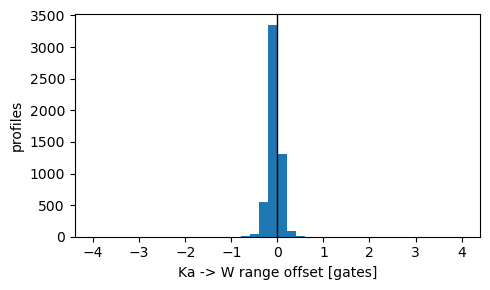

In [15]:
off = range_registration_offset(ze_ka, ze_w, mask)

if off.size < 20:
    print("Too few profiles — loosen min_gates or use a thicker-cloud day.")
else:
    med = np.median(off)
    iqr = np.subtract(*np.percentile(off, [75, 25]))
    print(f"median offset : {med:+.3f} gate ({med*dr:+.1f} m)")
    print(f"IQR           : {iqr:.3f} gate")

    plt.figure(figsize=(5,3))
    plt.hist(off, bins=40); plt.axvline(0, color="k", lw=1)
    plt.xlabel("Ka -> W range offset [gates]"); plt.ylabel("profiles")
    plt.tight_layout(); plt.show()

In [21]:
ze_w = ds["Ze_W"].transpose("Time", "range").sel(range=slice(0, 4000)).values

## ???? But end result is fine. ρ(1) near 0 → truly independent, done. ρ(1) around 0.3–0.5 → your σ_DWR is 15–40% higher than measured. Either way it's a number for Chapter 5, not a blocker.

RangeRes is the nominal resolution, c/(2B). The actual impulse response is wider, because FMCW processing applies a window function (Hann or similar) before the FFT. A Hann window broadens the main lobe to roughly 1.5–2 bins. So adjacent gates can still share signal even though spacing equals nominal resolution — metadata cannot tell you this.

There's a nice consistency here: window functions exist precisely to suppress sidelobes. Your weak sidelobe correlations (0.12, 0.22) suggest a good window is being applied — which implies main-lobe broadening — which implies some gate-to-gate correlation. The two findings fit together.

Five-minute empirical check, on clear-air gates well above cloud top:

In [22]:
def range_autocorr(field, mask, max_lag=5):
    """Lag-k correlation along RANGE, on noise-only gates."""
    x = np.asarray(field, float).copy()
    x[~np.asarray(mask, bool)] = np.nan
    x = x - np.nanmean(x, axis=0, keepdims=True)   # remove the r^2 range trend
    out = []
    for lag in range(1, max_lag + 1):
        a, b = x[:, :-lag].ravel(), x[:, lag:].ravel()
        g = np.isfinite(a) & np.isfinite(b)
        out.append(np.corrcoef(a[g], b[g])[0, 1] if g.sum() > 100 else np.nan)
    return np.array(out)

# clear air: 5 gates above the highest cloudy gate in each profile
clear = np.zeros_like(mask)
for t, m in enumerate(mask):
    if m.any():
        clear[t, np.flatnonzero(m)[-1] + 5:] = True

print("rho(1..5) =", np.round(range_autocorr(ze_w, clear), 3))

C:\Users\geron\AppData\Local\Temp\ipykernel_22228\2018621678.py:5: RuntimeWarning: Mean of empty slice
  x = x - np.nanmean(x, axis=0, keepdims=True)   # remove the r^2 range trend


rho(1..5) = [0.245   nan   nan   nan   nan]


## Radar Placement Difference d?